In [1]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from model.tepSystemModel   import SystemModel
from preProcessingDataTEP   import PreProcessData
from prettytable            import PrettyTable

from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json


2025-05-04 21:19:38.410603: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-05-04 21:19:38.592965: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-04 21:19:39.344406: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-05-04 21:19:39.344507: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerro

In [2]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 100
normalizeHI             = True
showRedundantShutdown   = False

#### Preprocessing data

In [3]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir              = outputDir, 
                                                   name             = "data/teps.h5",
                                                   case             = "all", 
                                                   reduceSampleRate = True, 
                                                   removeHigherThr  = False)

withRULData         = preData.addRULAndEnvironment(rawData)
# withoutInitRawData  = preData.removeInitState(inData= withRULData)



# ---------------------------
# For data
cleanData           = preData.cleanData(rawSignal           =   withRULData,
                                        columnName          =   preData.allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
norData             = preData.normalizeDataEachModes(rawData    = cleanData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"] + ["rul"])    # Normalize the data



Process:119598||2025-05-04 21:19:41,004-INFO [preProcessingDataTEP.py:loadDataFromH5Format():357]:Loading data from H5 files ...
Process:119598||2025-05-04 21:19:42,060-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:119598||2025-05-04 21:19:42,271-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:119598||2025-05-04 21:19:42,272-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:119598||2025-05-04 21:19:42,272-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:119598||2025-05-04 21:19:42,273-INFO [preProcessingDataTEP.py:normalizeDataEachModes():800]:Normalizing the data ...


In [4]:
# curCase     = 2
# caseData    = rawData[curCase]
# aiLogger.debug(f"------------------------- The case {curCase}")

# for idx in range(100):
#     curId = idx + 1
    
#     # Filter data directly for the current Id
#     curData = caseData[caseData["Id"] == curId]
    
#     if not curData.empty:
#         # Safely access the last value of "Stripper Level"
#         print(curData["Stripper Level"].iloc[-1])
#     else:
#         print(f"Id {curId} not found in the data")

#### Declare the model

In [5]:
# config["component"] = "Reac"
# vaeReac = mainModel(config = config)
# vaeReac.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
# # vaeReac.build(input_shape=(None, config["seqLength"], config["inReac"]))
# vaeReac.summary()
# vaeReac.load_weights(outputDir + "checkpoint/bestModel30Reac/")

In [6]:
# config["component"] = "Sep"
# vaeSep = mainModel(config = config)
# vaeSep.build(input_shape=[(None, config["seqLength"], config["inSep"]), (None, 1, config["inSep"]), (None, 1)])
# vaeSep.summary()
# vaeSep.load_weights(outputDir + "checkpoint/bestModel31Sep/")

In [7]:
# config["component"] = "Strip"
# vaeStrip = mainModel(config = config)
# vaeStrip.build(input_shape=[(None, config["seqLength"], config["inStrip"]), (None, 1, config["inStrip"]), (None, 1)])
# vaeStrip.summary()
# vaeStrip.load_weights(outputDir + "checkpoint/bestModel32Strip/")

In [8]:
config["component"] = "Sys"
vaeSys = SystemModel(config = config)
vaeSys.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
vaeSys.summary()


# modelDirComp1 = outputDir + "checkpoint/" + "bestModelReacNewData"
# modelDirComp2 = outputDir + "checkpoint/" + "bestModelSepNewData"
# modelDirComp3 = outputDir + "checkpoint/" + "bestModelStripNewData"
# modelDirSys   = outputDir + "checkpoint/" + "bestModelSysNewData"


modelDirComp1 = outputDir + "checkpoint/" + "bestModel34Reac"
modelDirComp2 = outputDir + "checkpoint/" + "bestModel35Sep"
modelDirComp3 = outputDir + "checkpoint/" + "bestModel36Strip"
modelDirSys   = outputDir + "checkpoint/" + "bestModel38Sys"
vaeSys.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)

2025-05-04 21:19:45.042526: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-04 21:19:45.048494: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-04 21:19:45.048697: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-04 21:19:45.049170: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:119598||2025-05-04 21:19:46,643-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():923]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip
Process:119598||2025-05-04 21:19:46,681-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():962]:Loaded the model at the direction:('/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip') and freezed it successfully!!!
Process:119598||2025-05-04 21:19:46,696-DEBUG [tepSystemModel.py:__init__():313]:The shape of hiSelectionInput (None, 120)
Process:119598||2025-05-04 21:19:46,736-DEBUG [tepSystemModel.py:_

-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
Model: "system_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection (SensorSel  multiple                 135       
 ection)                                                         
                                                                 
 sensor_selection_1 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 sensor_selection_2 (SensorS  multiple                 135       
 election)                    

Process:119598||2025-05-04 21:19:48,156-INFO [tepSystemModel.py:load_weights():888]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys
Process:119598||2025-05-04 21:19:48,202-INFO [tepSystemModel.py:load_weights():920]:Loaded the model at the direction:/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys successfully!!!


### MAKS EACH COMPONENT IN EACH ENVIRONMENT

#### Reactor

In [9]:
binaryMaskReac, probsReac     = vaeSys.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 26.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         |      1.0      |  1.0   |
| 1  |         A Feed         | 1.0593292e-12 |  0.0   |
| 2  |      A and C Feed      |      1.0      |  1.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 1.0623663e-12 |  0.0   |
| 7  |   Condenser Coolant    |  1.065079e-12 |  0.0   |
| 8  |       msv A Feed       |  1.059976e-12 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       |      1.0      |  1.0   |
| 11 |    msv A and C Feed    |      1.0      |  1.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Separator

In [10]:
binaryMaskReac, probsReac     = vaeSys.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)



The number of selected sensor in the environment 1 is 13.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 4.6886475e-13 |  0.0   |
| 1  |         A Feed         | 4.6633183e-13 |  0.0   |
| 2  |      A and C Feed      | 4.6340227e-13 |  0.0   |
| 3  |         Purge          | 4.6123657e-13 |  0.0   |
| 4  |       Separator        |  4.627496e-13 |  0.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 4.5894007e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 4.6479915e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 4.6254927e-13 |  0.0   |
| 11 |    msv A and C Feed    | 4.5658963e-13 |  0.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Stripper

In [11]:
binaryMaskReac, probsReac     = vaeSys.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 19.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 1.7232655e-13 |  0.0   |
| 1  |         A Feed         |  1.670584e-13 |  0.0   |
| 2  |      A and C Feed      | 1.9034903e-13 |  0.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        | 1.9865823e-13 |  0.0   |
| 6  |    Reactor Coolant     | 1.6826333e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 1.6601526e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 1.6638454e-13 |  0.0   |
| 11 |    msv A and C Feed    | 1.7078405e-13 |  0.0   |
| 12 |      Recycle Flow      | 1.5469925e-13 |  0.0   |
| 13 |   Reactor Feed Rate   

### HI FOR EACH ENVIRONMENT

#### Environment 2

In [12]:
environmentIdx      = 2
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # aiLogger.debug(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

# aiLogger.debug((timeDraw[0].shape))
if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:119598||2025-05-04 21:19:48,973-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------


2025-05-04 21:19:50.114626: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2025-05-04 21:19:50.979919: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-05-04 21:19:50.980325: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-05-04 21:19:50.980346: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2025-05-04 21:19:50.980748: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-05-04 21:19:50.980801: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
2025-05-04 21:19:51.583661: I tensorflow/stream_executor/cuda/c

Getting the HI at the idx 2
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------


Process:119598||2025-05-04 21:19:52,237-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1328, 1, 45)
(1328, 128, 45)
(1328, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1328, 1, 45)
(1328, 128, 45)
(1328, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1328, 1, 45)
(1328, 128, 45)
(1328, 128, 45)
-------------------------------


... (190 outputs left out)

Process:119598||2025-05-04 21:20:34,416-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------


Process:119598||2025-05-04 21:20:34,927-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------


In [20]:
import plotly.graph_objects as go
import os
def draw2DMultipleY(
                    xCoor       = [0,10],
                    yCoor       = [[0,10],[10,1]],
                    yLabel      = "Y Value",
                    xLabel      = "Time Unit",
                    title       = "XYAxis",
                    saveFig     = False,
                    direction   = "checkpoint/",
                    savedName   = "default",
                    useLegend   = True,
                    legend      = ["line1","line2"],
                    color       = ["blue","green"],
                    yLim       = [],):
    
    plt.figure()
    for idx,yValue in enumerate(yCoor):
        plt.plot(xCoor,yValue, color=color[idx])

    plt.title(title)
    # plt.xlabel(xLabel)
    # plt.ylabel(yLabel)

    if len(yLim) != 0:
        plt.ylim(yLim)
    if useLegend:
        plt.legend(legend, loc='upper left')
    plt.grid(True)
    if saveFig:
        
        if not os.path.exists(direction):
            os.makedirs(direction)
        plt.savefig(direction + savedName + '.png')
        plt.close()
    else:
        plt.show()


def draw2DMultipleY_plotly(
        xCoor=[0, 10],
        yCoor=[[0, 10], [10, 1]],
        yLabel="Y Value",
        xLabel="Time Unit",
        title="XYAxis",
        saveFig=False,
        direction="checkpoint/",
        savedName="default",
        useLegend=True,
        legend=["line1", "line2"],
        color=["blue", "green"],
        yLim=[]
    ):

    fig = go.Figure()

    for idx, yValue in enumerate(yCoor):
        fig.add_trace(go.Scatter(
            x=xCoor,
            y=yValue,
            mode='lines',
            name=legend[idx] if useLegend else None,
            line=dict(color=color[idx])
        ))

    # fig.update_layout(
    #     title=title,
    #     xaxis_title=xLabel,
    #     yaxis_title=yLabel,
    #     yaxis=dict(range=yLim if yLim else None),
    #     showlegend=useLegend
    # )
    fig.update_layout(
    title=title,
    xaxis_title=xLabel,
    yaxis_title=yLabel,
    yaxis=dict(range=yLim if yLim else None),
    showlegend=useLegend,
    plot_bgcolor='white',
    paper_bgcolor='white'
)


    if saveFig:
        if not os.path.exists(direction):
            os.makedirs(direction)
        fig.write_image(f"{direction}{savedName}.png")
    else:
        fig.show()


In [21]:
drawId = 2
curTimeDraw = timeDraw[drawId]
hi1Draw = hiEnv1["Reac"][drawId]
hi2Draw = hiEnv1["Sep"][drawId]
hi3Draw = hiEnv1["Strip"][drawId]
hiSysDraw = hiEnv1["Sys"][drawId]

draw2DMultipleY_plotly(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1.1])


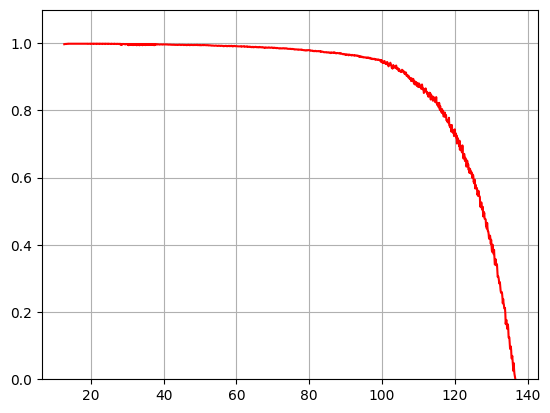

In [15]:
draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hiSysDraw], title = None, xLabel = "Cycle", yLabel = "System HIs", color = ["red"], useLegend= False, yLim = [0,1.1])

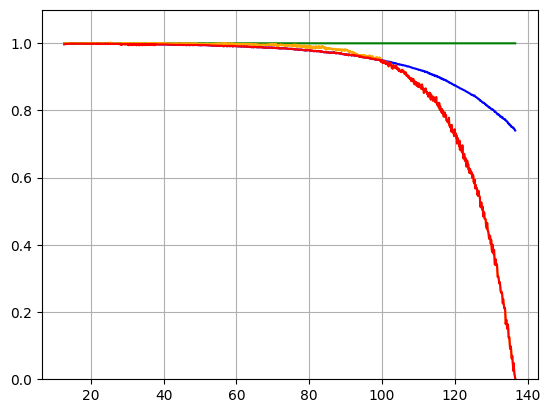

In [16]:

draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw, hiSysDraw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange", "red"], useLegend= False, yLim = [0,1.1])


In [17]:
1=2
aaa =v

SyntaxError: cannot assign to literal here. Maybe you meant '==' instead of '='? (1133068576.py, line 1)

In [ ]:
# plot1 = MatPlot() 
# plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [ ]:
# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw,color=['g'], numRow=20, numCol=5)

In [ ]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 3

In [22]:
environmentIdx      = 3
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:119598||2025-05-04 21:48:48,596-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------


Process:119598||2025-05-04 21:48:49,100-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------


Process:119598||2025-05-04 21:48:49,502-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------
Getting the HI at the idx 3
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------


... (190 outputs left out)

Process:119598||2025-05-04 21:49:31,825-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------


Process:119598||2025-05-04 21:49:32,305-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------


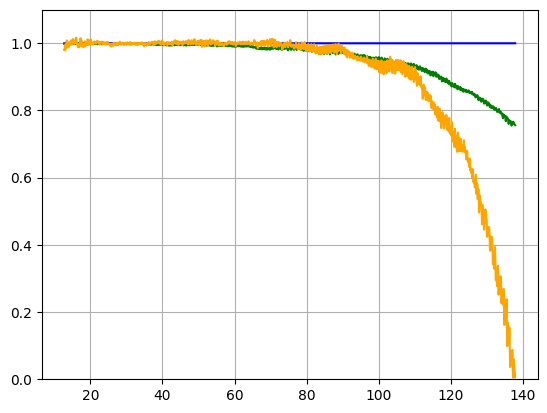

In [43]:
drawId = 15
curTimeDraw = timeDraw[drawId]
hi1Draw = hiEnv1["Reac"][drawId]
hi2Draw = hiEnv1["Sep"][drawId]
hi3Draw = hiEnv1["Strip"][drawId]
hiSysDraw = hiEnv1["Sys"][drawId]

draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1.1])

draw2DMultipleY_plotly(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1.1])


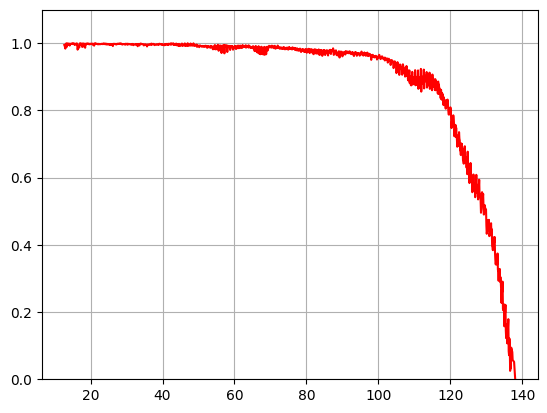

In [24]:
draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hiSysDraw], title = None, xLabel = "Cycle", yLabel = "System HIs", color = ["red"], useLegend= False, yLim = [0,1.1])

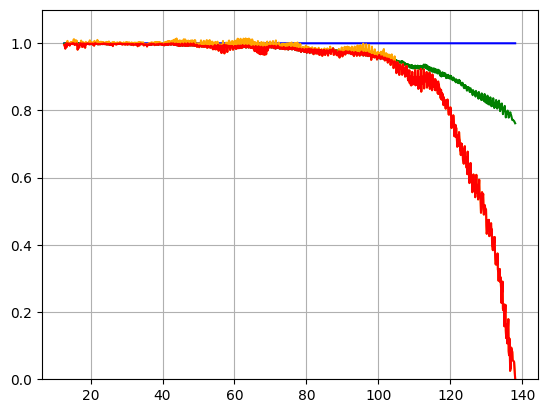

In [25]:

draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw, hiSysDraw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange", "red"], useLegend= False, yLim = [0,1.1])


In [ ]:
# plot3 = MatPlot() 
# plot3.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX=timeDraw, color=['g','b', 'y','r'], numRow=20, numCol=5)

In [ ]:
# plot4 = MatPlot()
# plot4.subPlotMultiImg(inY = [ rulEnv1["Sys"]],  inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [ ]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 4

In [44]:
environmentIdx      = 4
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:119598||2025-05-04 22:06:57,048-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------


Process:119598||2025-05-04 22:06:57,516-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------


Process:119598||2025-05-04 22:06:58,029-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------


... (190 outputs left out)

Process:119598||2025-05-04 22:07:34,626-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


-------------------------------
(3, 45)
(1077, 1, 45)
(1077, 128, 45)
(1077, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1077, 1, 45)
(1077, 128, 45)
(1077, 128, 45)
-------------------------------
Getting the HI at the idx 99
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------


Process:119598||2025-05-04 22:07:35,032-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------


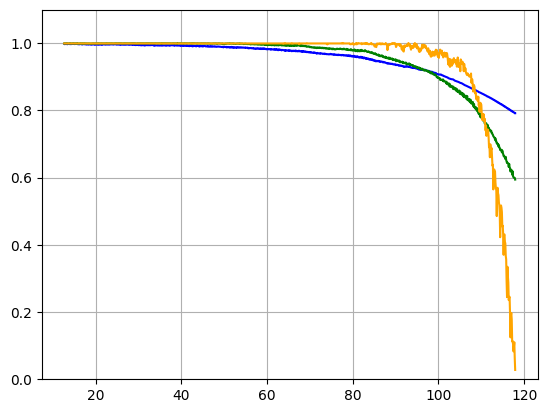

In [45]:
drawId = 1
curTimeDraw = timeDraw[drawId]
hi1Draw = hiEnv1["Reac"][drawId]
hi2Draw = hiEnv1["Sep"][drawId]
hi3Draw = hiEnv1["Strip"][drawId]
hiSysDraw = hiEnv1["Sys"][drawId]

draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1.1])

draw2DMultipleY_plotly(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1.1])


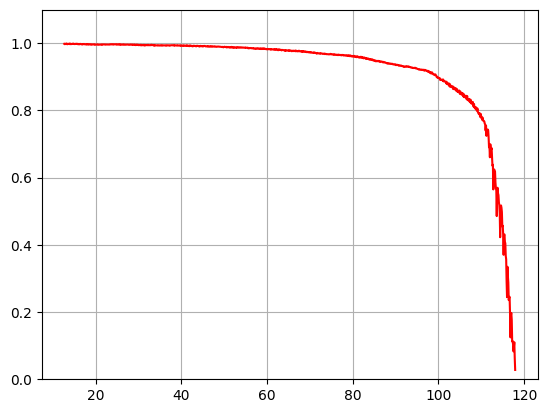

In [46]:
draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hiSysDraw], title = None, xLabel = "Cycle", yLabel = "System HIs", color = ["red"], useLegend= False, yLim = [0,1.1])

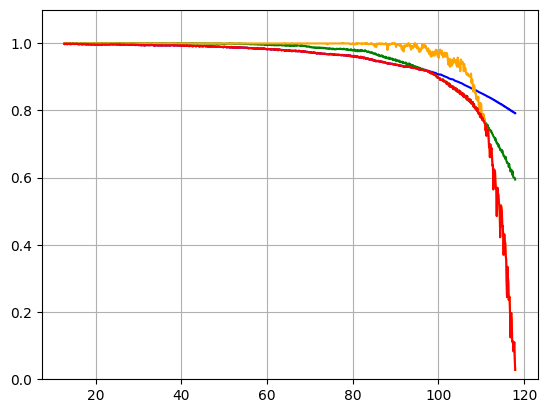

In [ ]:
draw2DMultipleY(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw, hiSysDraw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange", "red"], useLegend= False, yLim = [0,1.1])


In [ ]:
# plot5 = MatPlot() 
# plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [ ]:
# plot6 = MatPlot()
# plot6.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [ ]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])